# 성수 네이버 플레이스 리뷰 데이터 Descriptive Statistics

## 목적
성수 지역 음식점의 네이버 플레이스 방문자 리뷰 표본을 이용하여 리뷰 데이터의 구조와 분포를 파악하고 기초통계량 및 요약 차트를 생성합니다.

업로드된 원본 파일을 확인한 결과:
- 총 리뷰: **5,880개**
- 음식점: **31개**
- 작성자: **5,384명**
- 리뷰 기간: **2025-11-11 ~ 2026-09-26**
- 컬럼: review_id, place_id, restaurant_name, category, author, review_date, rating, waiting_time, reservation, verification, review_text

이 노트북에서는 원본 데이터를 수정하지 않고 분석용 DataFrame에서 전처리합니다.


## 1. 라이브러리


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [18]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

## 2. 데이터 불러오기

CSV 파일과 이 노트북을 같은 폴더에 두는 것을 기준으로 작성했습니다.
파일명을 바꾸었다면 `FILE` 값만 수정하면 됩니다.


In [3]:
FILE = "naver_seongsu_reviews.csv"

reviews = pd.read_csv(FILE, encoding="utf-8-sig")

print("Shape:", reviews.shape)
display(reviews.head())


Shape: (5880, 11)


,review_id,place_id,restaurant_name,category,author,review_date,rating,waiting_time,reservation,verification,review_text
0,fd177fb29fe29e2f37f166a5472d9de39b20574dd4afdf...,1130497590,연남토마 성수점,퓨전음식,sklee37,2026-09-26,5.00,바로 입장,예약 없이 이용,영수증,맛있어요~ 서울숲과가까워요
1,425c2267cfd18581410a672fb7ad5bc5c7832ee8624aa1...,1130497590,연남토마 성수점,퓨전음식,숲속작은집40,2026-09-26,5.00,10분 이내,예약 없이 이용,영수증,성수동 연나토마\n야키니쿠덮밥 너무 맛있습니다. 안심돈카츠도 맛나네요.
2,b0d3076770db1b70c677759e6a1452d6f4e95ec488c33c...,1130497590,연남토마 성수점,퓨전음식,Dicos39,2026-09-26,5.00,30분 이내,예약 없이 이용,영수증,생각보다 내부가 커서 테이블 회전은 빠른 편입니다. 앞에 7팀 있었는데 30분 정도...
3,f9803cd3e33be367894eb9e07dc98608174a475c17dabf...,1130497590,연남토마 성수점,퓨전음식,시리우스4571,2026-09-26,5.00,바로 입장,예약 후 이용,영수증,"맛이 깔끔하고, 아늑한 분위기 만땅 공감입니다.\n식당이 번잡하지 않아 좋았습니다...."
4,a7e41be7832d3d929eb803732286fd2cd140ec0245073f...,1130497590,연남토마 성수점,퓨전음식,YJ6732,2026-09-26,5.00,30분 이내,예약 없이 이용,영수증,일단 음식맛이 다 맛있어요\n직원분들 친절하십니다


## 3. 데이터 구조 확인


In [4]:
print("Columns:")
print(reviews.columns.tolist())

print("\nData types:")
print(reviews.dtypes)

print("\nBasic information:")
reviews.info()


Columns:
['review_id', 'place_id', 'restaurant_name', 'category', 'author', 'review_date', 'rating', 'waiting_time', 'reservation', 'verification', 'review_text']

Data types:
review_id           object
place_id             int64
restaurant_name     object
category            object
author              object
review_date         object
rating             float64
waiting_time        object
reservation         object
verification        object
review_text         object
dtype: object

Basic information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5880 entries, 0 to 5879
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   review_id        5880 non-null   object 
 1   place_id         5880 non-null   int64  
 2   restaurant_name  5880 non-null   object 
 3   category         5880 non-null   object 
 4   author           5880 non-null   object 
 5   review_date      5880 non-null   object 
 6   rating       

## 4. 표본 규모 확인


In [5]:
n_reviews = len(reviews)
n_restaurants = reviews["restaurant_name"].nunique()
n_reviewers = reviews["author"].nunique()
n_unique_reviews = reviews["review_id"].nunique()

print("Number of reviews:", n_reviews)
print("Number of restaurants:", n_restaurants)
print("Number of reviewers:", n_reviewers)
print("Unique review IDs:", n_unique_reviews)

print("\nDuplicated review IDs:",
      reviews["review_id"].duplicated().sum())


Number of reviews: 5880
Number of restaurants: 31
Number of reviewers: 5384
Unique review IDs: 5880

Duplicated review IDs: 0


## 5. 날짜 전처리 및 조사기간 확인

`review_date`를 날짜형으로 변환하고 연도, 월, 연월 변수를 만듭니다.


In [6]:
reviews["review_date"] = pd.to_datetime(
    reviews["review_date"],
    errors="coerce"
)

reviews["year"] = reviews["review_date"].dt.year
reviews["month"] = reviews["review_date"].dt.month
reviews["year_month"] = reviews["review_date"].dt.to_period("M")

print("Earliest review:", reviews["review_date"].min())
print("Latest review:", reviews["review_date"].max())


Earliest review: 2025-11-11 00:00:00
Latest review: 2026-09-26 00:00:00


## 6. 결측치 확인


In [7]:
missing = pd.DataFrame({
    "Missing": reviews.isna().sum(),
    "Missing Rate (%)": reviews.isna().mean() * 100
})

missing = missing.sort_values(
    "Missing Rate (%)",
    ascending=False
)

display(missing.round(2))


,Missing,Missing Rate (%)
verification,675,11.48
waiting_time,624,10.61
reservation,553,9.40
rating,177,3.01
review_id,0,0.00
place_id,0,0.00
restaurant_name,0,0.00
category,0,0.00
author,0,0.00
review_date,0,0.00


### 결측치 해석 시 주의

별점, 웨이팅 시간, 예약 여부, 방문 인증 방식은 모든 리뷰에서 반드시 기록되는 항목이 아니므로 결측치 자체도 데이터 특성입니다.  
따라서 descriptive statistics에서는 임의로 0이나 특정 범주로 대체하지 않고, 유효 관측치 수(N)를 함께 제시합니다.


## 7. 별점 기초통계량


In [8]:
reviews["rating"] = pd.to_numeric(
    reviews["rating"],
    errors="coerce"
)

rating_stats = reviews["rating"].agg([
    "count",
    "mean",
    "std",
    "median",
    "min",
    "max"
])

display(rating_stats.to_frame("Rating").T.round(2))


,count,mean,std,median,min,max
Rating,"5,703.00",4.93,0.33,5.00,0.50,5.00


### 별점별 리뷰 수와 비율


In [9]:
rating_distribution = (
    reviews["rating"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

rating_distribution["Percent (%)"] = (
    rating_distribution["Count"] / len(reviews) * 100
)

display(rating_distribution.round(2))


,Count,Percent (%)
rating,,
0.50,7,0.12
1.00,8,0.14
2.00,6,0.10
2.50,1,0.02
3.00,23,0.39
3.50,12,0.20
4.00,154,2.62
4.50,140,2.38
5.00,5352,91.02


## 8. 음식점별 리뷰 수와 별점


In [10]:
restaurant_summary = (
    reviews
    .groupby(["place_id", "restaurant_name"])
    .agg(
        Review_Count=("review_id", "count"),
        Rated_Review_Count=("rating", "count"),
        Mean_Rating=("rating", "mean"),
        Median_Rating=("rating", "median"),
        Unique_Reviewers=("author", "nunique")
    )
    .reset_index()
    .sort_values("Review_Count", ascending=False)
)

display(restaurant_summary.round(2))


,place_id,restaurant_name,Review_Count,Rated_Review_Count,Mean_Rating,Median_Rating,Unique_Reviewers
7,1189077446,미도인 성수,199,199,4.98,5.00,191
27,2073097145,안목 성수,199,199,4.92,5.00,198
16,1561895045,성수노루,199,199,4.93,5.00,196
0,1026594418,bd버거 성수역연무장길 점심저녁,198,198,4.97,5.00,196
28,2079753084,오몬자 성수점,198,198,4.99,5.00,197
10,1282228632,문화식당,198,198,4.99,5.00,196
8,1192614910,누메로뜨레쓰,198,198,4.96,5.00,194
30,2087098555,도돗,198,198,4.86,5.00,185
2,1059490459,이가네양꼬치 성수직영점,198,105,4.74,5.00,197
4,1133107813,플르서라구뜨,198,114,4.98,5.00,194


## 9. 업종(category) 분포


In [11]:
category_summary = (
    reviews
    .groupby("category")
    .agg(
        Review_Count=("review_id", "count"),
        Restaurant_Count=("place_id", "nunique"),
        Mean_Rating=("rating", "mean")
    )
    .sort_values("Review_Count", ascending=False)
)

category_summary["Review_Percent (%)"] = (
    category_summary["Review_Count"] /
    len(reviews) * 100
)

display(category_summary.round(2))


,Review_Count,Restaurant_Count,Mean_Rating,Review_Percent (%)
category,,,,
일식당,1357,7,4.94,23.08
양식,978,5,4.96,16.63
햄버거,581,3,4.93,9.88
한식,580,3,4.95,9.86
"육류,고기요리",256,2,4.79,4.35
"곱창,막창,양",199,1,4.93,3.38
국밥,199,1,4.92,3.38
양꼬치,198,1,4.74,3.37
이탈리아음식,198,1,4.96,3.37


## 10. 웨이팅 시간 분포


In [12]:
waiting_summary = pd.DataFrame({
    "Count": reviews["waiting_time"].value_counts(dropna=False),
    "Percent (%)": reviews["waiting_time"].value_counts(
        dropna=False,
        normalize=True
    ) * 100
})

display(waiting_summary.round(2))


,Count,Percent (%)
waiting_time,,
바로 입장,4536,77.14
NaN,624,10.61
10분 이내,475,8.08
30분 이내,245,4.17


## 11. 예약 여부 분포


In [13]:
reservation_summary = pd.DataFrame({
    "Count": reviews["reservation"].value_counts(dropna=False),
    "Percent (%)": reviews["reservation"].value_counts(
        dropna=False,
        normalize=True
    ) * 100
})

display(reservation_summary.round(2))


,Count,Percent (%)
reservation,,
예약 없이 이용,4378,74.46
예약 후 이용,949,16.14
NaN,553,9.40


## 12. 방문 인증 방식 분포


In [14]:
verification_summary = pd.DataFrame({
    "Count": reviews["verification"].value_counts(dropna=False),
    "Percent (%)": reviews["verification"].value_counts(
        dropna=False,
        normalize=True
    ) * 100
})

display(verification_summary.round(2))


,Count,Percent (%)
verification,,
영수증,4938,83.98
NaN,675,11.48
예약,267,4.54


## 13. 리뷰 텍스트 길이

텍스트 감성분석이나 NLP를 이후 수행한다면 리뷰 길이도 표본의 기본 특성으로 확인할 수 있습니다.


In [15]:
reviews["review_length"] = (
    reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.len()
)

text_stats = reviews["review_length"].agg([
    "count",
    "mean",
    "std",
    "median",
    "min",
    "max"
])

display(text_stats.to_frame("Review Text Length").T.round(2))


,count,mean,std,median,min,max
Review Text Length,"5,880.00",58.73,50.91,47.00,1.00,400.00


## 14. 최종 리뷰 데이터 Descriptive Statistics 표


In [16]:
summary_rows = []

rating = reviews["rating"].dropna()
review_length = reviews["review_length"].dropna()

summary_rows.append({
    "Variable": "Rating",
    "N": len(rating),
    "Mean": rating.mean(),
    "SD": rating.std(),
    "Median": rating.median(),
    "Min": rating.min(),
    "Max": rating.max()
})

summary_rows.append({
    "Variable": "Review Text Length",
    "N": len(review_length),
    "Mean": review_length.mean(),
    "SD": review_length.std(),
    "Median": review_length.median(),
    "Min": review_length.min(),
    "Max": review_length.max()
})

review_stats = pd.DataFrame(summary_rows)

display(review_stats.round(2))


,Variable,N,Mean,SD,Median,Min,Max
0,Rating,5703,4.93,0.33,5.00,0.50,5.00
1,Review Text Length,5880,58.73,50.91,47.00,1.00,400.00


## 15. Figure 1 — 음식점별 리뷰 수


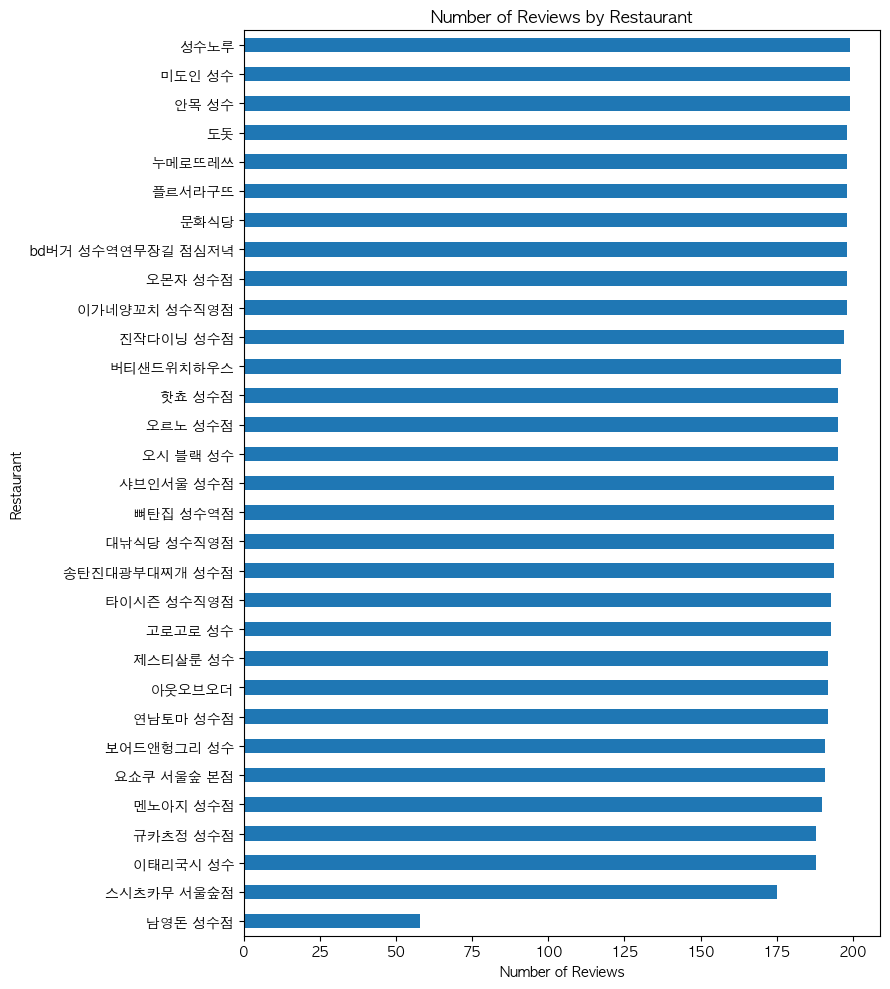

In [19]:
review_counts = (
    reviews["restaurant_name"]
    .value_counts()
    .sort_values()
)

review_counts.plot(
    kind="barh",
    figsize=(9, 10)
)

plt.xlabel("Number of Reviews")
plt.ylabel("Restaurant")
plt.title("Number of Reviews by Restaurant")
plt.tight_layout()
plt.show()


## 16. Figure 2 — 별점 분포


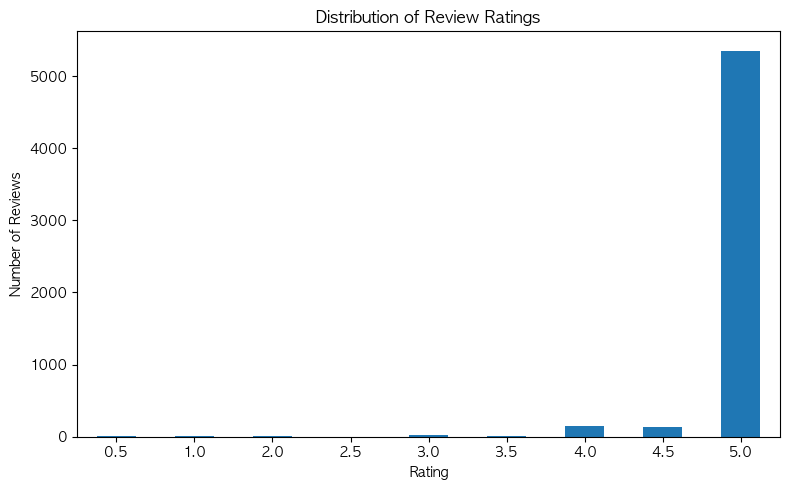

In [20]:
rating_counts = (
    reviews["rating"]
    .dropna()
    .value_counts()
    .sort_index()
)

rating_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Review Ratings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 17. Figure 3 — 웨이팅 시간 분포


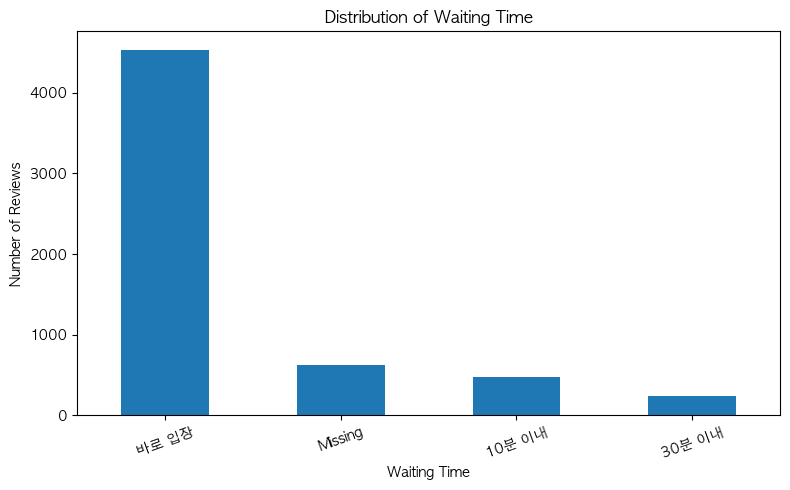

In [21]:
waiting_counts = (
    reviews["waiting_time"]
    .fillna("Missing")
    .value_counts()
)

waiting_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Waiting Time")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Waiting Time")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 18. Figure 4 — 예약 여부


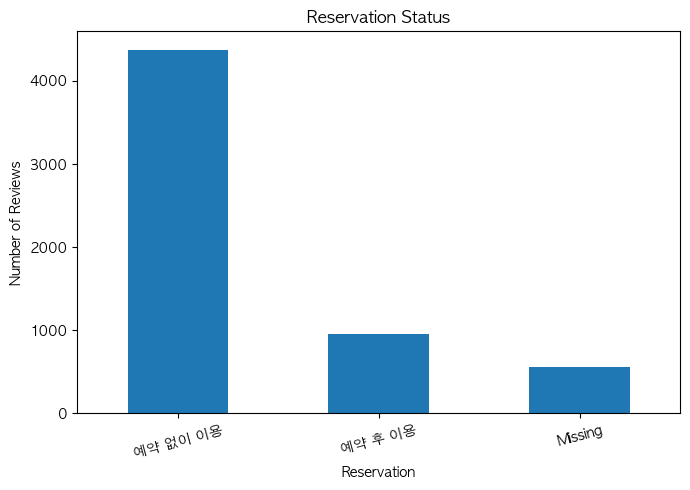

In [22]:
reservation_counts = (
    reviews["reservation"]
    .fillna("Missing")
    .value_counts()
)

reservation_counts.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.xlabel("Reservation")
plt.ylabel("Number of Reviews")
plt.title("Reservation Status")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 19. Figure 5 — 월별 리뷰 수


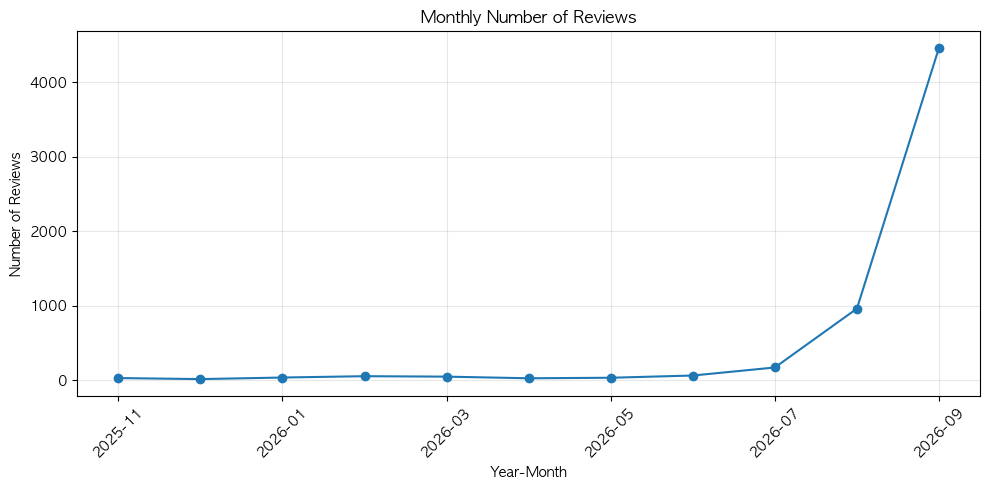

In [23]:
monthly_reviews = (
    reviews
    .dropna(subset=["review_date"])
    .groupby("year_month")
    .size()
)

monthly_reviews.index = monthly_reviews.index.astype(str)

monthly_reviews.plot(
    marker="o",
    figsize=(10, 5)
)

plt.xlabel("Year-Month")
plt.ylabel("Number of Reviews")
plt.title("Monthly Number of Reviews")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 20. Figure 6 — 업종별 리뷰 수


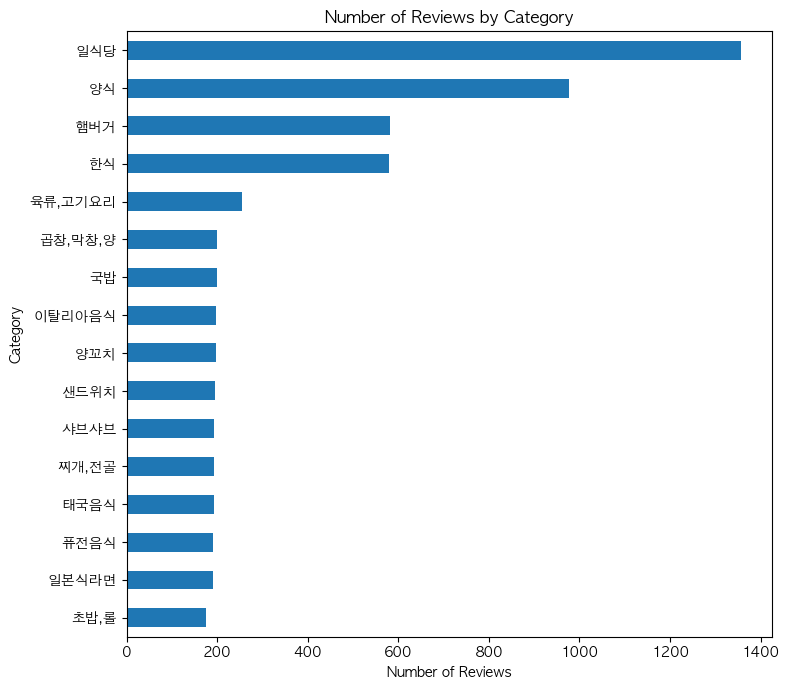

In [24]:
category_counts = (
    reviews["category"]
    .value_counts()
    .sort_values()
)

category_counts.plot(
    kind="barh",
    figsize=(8, 7)
)

plt.xlabel("Number of Reviews")
plt.ylabel("Category")
plt.title("Number of Reviews by Category")
plt.tight_layout()
plt.show()


## 21. 결과 CSV 저장


In [25]:
review_stats.round(2).to_csv(
    "review_descriptive_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

restaurant_summary.round(2).to_csv(
    "restaurant_review_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

category_summary.round(2).to_csv(
    "review_category_summary.csv",
    encoding="utf-8-sig"
)

missing.round(2).to_csv(
    "review_missing_values.csv",
    encoding="utf-8-sig"
)

print("결과 CSV 저장 완료")


결과 CSV 저장 완료


## 분석 시 핵심적으로 보고할 내용

이 표본은 31개 성수 지역 음식점에서 수집된 5,880개의 네이버 플레이스 방문자 리뷰로 구성됩니다.  
Descriptive statistics에서는 전체 리뷰 수와 음식점 수뿐 아니라 별점의 유효 관측치 수, 평균·표준편차·중앙값, 음식점별 리뷰 수, 업종별 리뷰 분포, 웨이팅 시간, 예약 여부 및 리뷰 작성 시점의 분포를 함께 확인합니다.

특히 `rating`, `waiting_time`, `reservation`, `verification`에는 결측치가 존재하므로 각 분석에서 전체 리뷰 수 5,880개와 실제 유효 관측치 수가 다를 수 있습니다. 따라서 평균이나 비율을 보고할 때 어떤 항목을 분모로 사용했는지 확인하는 것이 중요합니다.
